In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Zorg dat Python de root van je project kan vinden
sys.path.append(os.path.abspath('..'))

from models.fasterrcnn.wrapper import FasterRCNNWrapper
from utils.dataset import CustomCocoDataset
from utils.global_settings import ProjectPaths, BackdoorProperties, TrainingSettings, TriggerType

In [2]:
# --- 1. DATASET INITIALISATIE ---
print("Dataset laden in always_poison mode...")
poison_ds = CustomCocoDataset(
    image_folder=ProjectPaths.VALIDATION_IMAGES_DIR,
    annotations_file=ProjectPaths.VALIDATION_ANNOTATIONS_FILE,
    width=BackdoorProperties.RESIZE_WIDTH,
    height=BackdoorProperties.RESIZE_HEIGHT,
    mode="always_poison", # Cruciaal om de backdoor te testen
)

poison_dl = DataLoader(
    poison_ds,
    batch_size=4, # Een kleine batch is genoeg voor visuele inspectie
    num_workers=0, # Altijd 0 in Jupyter om multiprocessing crashes te voorkomen
    collate_fn=FasterRCNNWrapper.get_collate_fn(),
    pin_memory=True,
    shuffle=True, # Zodat je elke keer andere plaatjes ziet
)
print("Dataloader gereed.")

Dataset laden in always_poison mode...
Dataloader gereed.


In [3]:
def draw_styled_text(img, text, pos, font_scale=0.25, alpha=0.4, is_pred=False):
    font = cv2.FONT_HERSHEY_SIMPLEX
    thickness = 0
    text_color = (0, 0, 0) # Zwart
    bg_color = (150, 150, 255) if is_pred else (150, 255, 150) # Lichtrood (Pred) of Lichtgroen (GT)
    
    (w, h), baseline = cv2.getTextSize(text, font, font_scale, thickness)
    x, y = pos
    p = 1 # Minimale padding
    
    x1, y1 = x - p, y - h - p
    x2, y2 = x + w + p, y + baseline + p
    
    ih, iw = img.shape[:2]
    x1, x2 = np.clip([x1, x2], 0, iw - 1).astype(int)
    y1, y2 = np.clip([y1, y2], 0, ih - 1).astype(int)
    
    sub_img = img[y1:y2, x1:x2]
    if sub_img.shape[0] > 0 and sub_img.shape[1] > 0:
        rect_overlay = np.full(sub_img.shape, bg_color, dtype=np.uint8)
        res = cv2.addWeighted(sub_img, 1 - alpha, rect_overlay, alpha, 0)
        img[y1:y2, x1:x2] = res
    
    cv2.putText(img, text, (int(x), int(y)), font, font_scale, text_color, thickness, cv2.LINE_AA)

In [4]:
def inspect_inference_original_size(model_path, dataloader, dataset, num_images=2, conf_threshold=0.5, font_scale=0.25):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    id_to_cat = {v: k for k, v in dataset.cat_to_id_map.items()}
    
    # 1. Laad het model
    num_classes = dataset.get_total_classes_count() + 1
    wrapper = FasterRCNNWrapper(num_classes=num_classes)
    
    print(f"Laad weights van: {model_path}")
    if not os.path.exists(model_path):
        print(f"[ERROR] Model niet gevonden op {model_path}!")
        return
        
    checkpoint = torch.load(model_path, map_location=device)
    wrapper.set_weights(checkpoint["model_state_dict"])
    wrapper.model.to(device)
    wrapper.model.eval()
    
    # 2. Haal een batch op
    images, targets = next(iter(dataloader))
    
    for i in range(min(num_images, len(images))): 
        img_tensor = images[i]
        target = targets[i]
        
        # Haal de schaal op
        scale_w = target['image_scale'][0].item()
        scale_h = target['image_scale'][1].item()
        
        # 3. Voer het model uit
        with torch.inference_mode():
            prediction = wrapper.model([img_tensor.to(device)])[0]
            
        # Converteer tensor naar NumPy BGR afbeelding
        img_np = img_tensor.numpy().transpose(1, 2, 0)
        img_np = (img_np * 255).astype(np.uint8).copy()
        img_np = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
        
        # BEREKEN ORIGINELE DIMENSIES & RESIZE AFBEELDING
        orig_w = int(img_np.shape[1] / scale_w)
        orig_h = int(img_np.shape[0] / scale_h)
        img_np = cv2.resize(img_np, (orig_w, orig_h))
        
        # Vaste lijndikte voor de boxes
        box_thickness = 1
        
        # --- TEKEN GROUND TRUTH (GROEN) ---
        for box, label in zip(target['boxes'], target['labels']):
            x1 = int(box[0].item() / scale_w)
            y1 = int(box[1].item() / scale_h)
            x2 = int(box[2].item() / scale_w)
            y2 = int(box[3].item() / scale_h)
            
            class_name = id_to_cat.get(label.item(), str(label.item()))
            
            cv2.rectangle(img_np, (x1, y1), (x2, y2), (0, 255, 0), box_thickness)
            
            # Teken label strak boven de box met de VASTE font_scale
            draw_styled_text(img_np, f"{class_name}", (x1, max(y1 - 4, 10)), font_scale=font_scale)

        # --- TEKEN PREDICTIES (ROOD) ---
        pred_boxes = prediction['boxes'].cpu().numpy()
        pred_scores = prediction['scores'].cpu().numpy()
        pred_labels = prediction['labels'].cpu().numpy()
        
        mask = pred_scores > conf_threshold
        for box, score, label in zip(pred_boxes[mask], pred_scores[mask], pred_labels[mask]):
            x1 = int(box[0] / scale_w)
            y1 = int(box[1] / scale_h)
            x2 = int(box[2] / scale_w)
            y2 = int(box[3] / scale_h)
            
            class_name = id_to_cat.get(label, str(label))
            
            cv2.rectangle(img_np, (x1, y1), (x2, y2), (0, 0, 255), box_thickness)
            
            # Y-offset iets naar beneden gedrukt op basis van de font_scale, zodat het in de box valt
            y_offset = int(35 * font_scale) 
            draw_styled_text(img_np, f"{class_name} ({score:.2f})", (x1 + 2, y1 + y_offset), font_scale=font_scale, is_pred=True)

        # 4. Weergeven met Matplotlib
        img_final = cv2.cvtColor(img_np, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(8, 8), dpi=200) # Hoge DPI behouden voor scherpte van de kleine tekst
        plt.imshow(img_final)
        plt.title(f"Image ID: {target['image_id'].item()} | Originele Dimensies: {orig_w}x{orig_h} | Font Scale: {font_scale}")
        plt.axis('off')
        plt.tight_layout()
        plt.show()

Laad weights van: /home/koenb/Documents/Delft/year2/FODBackdooring/outputs/fl/../centralized/09-03-2026-20-24-34/best_model.pth


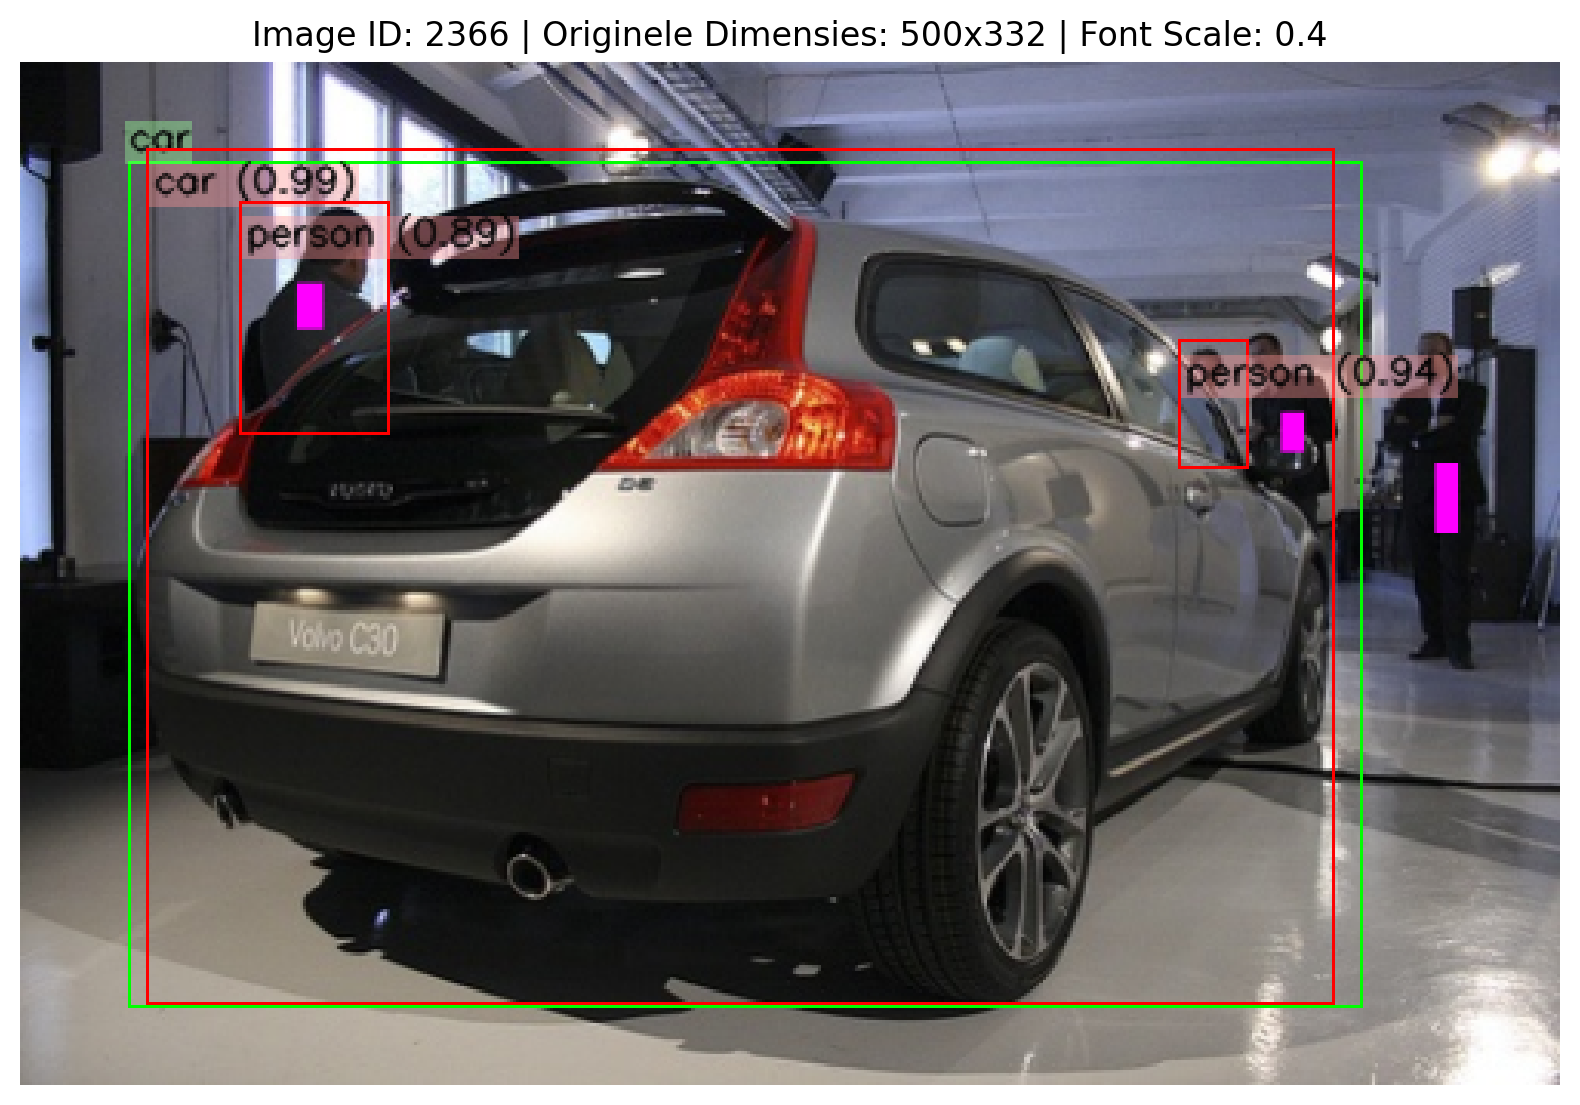

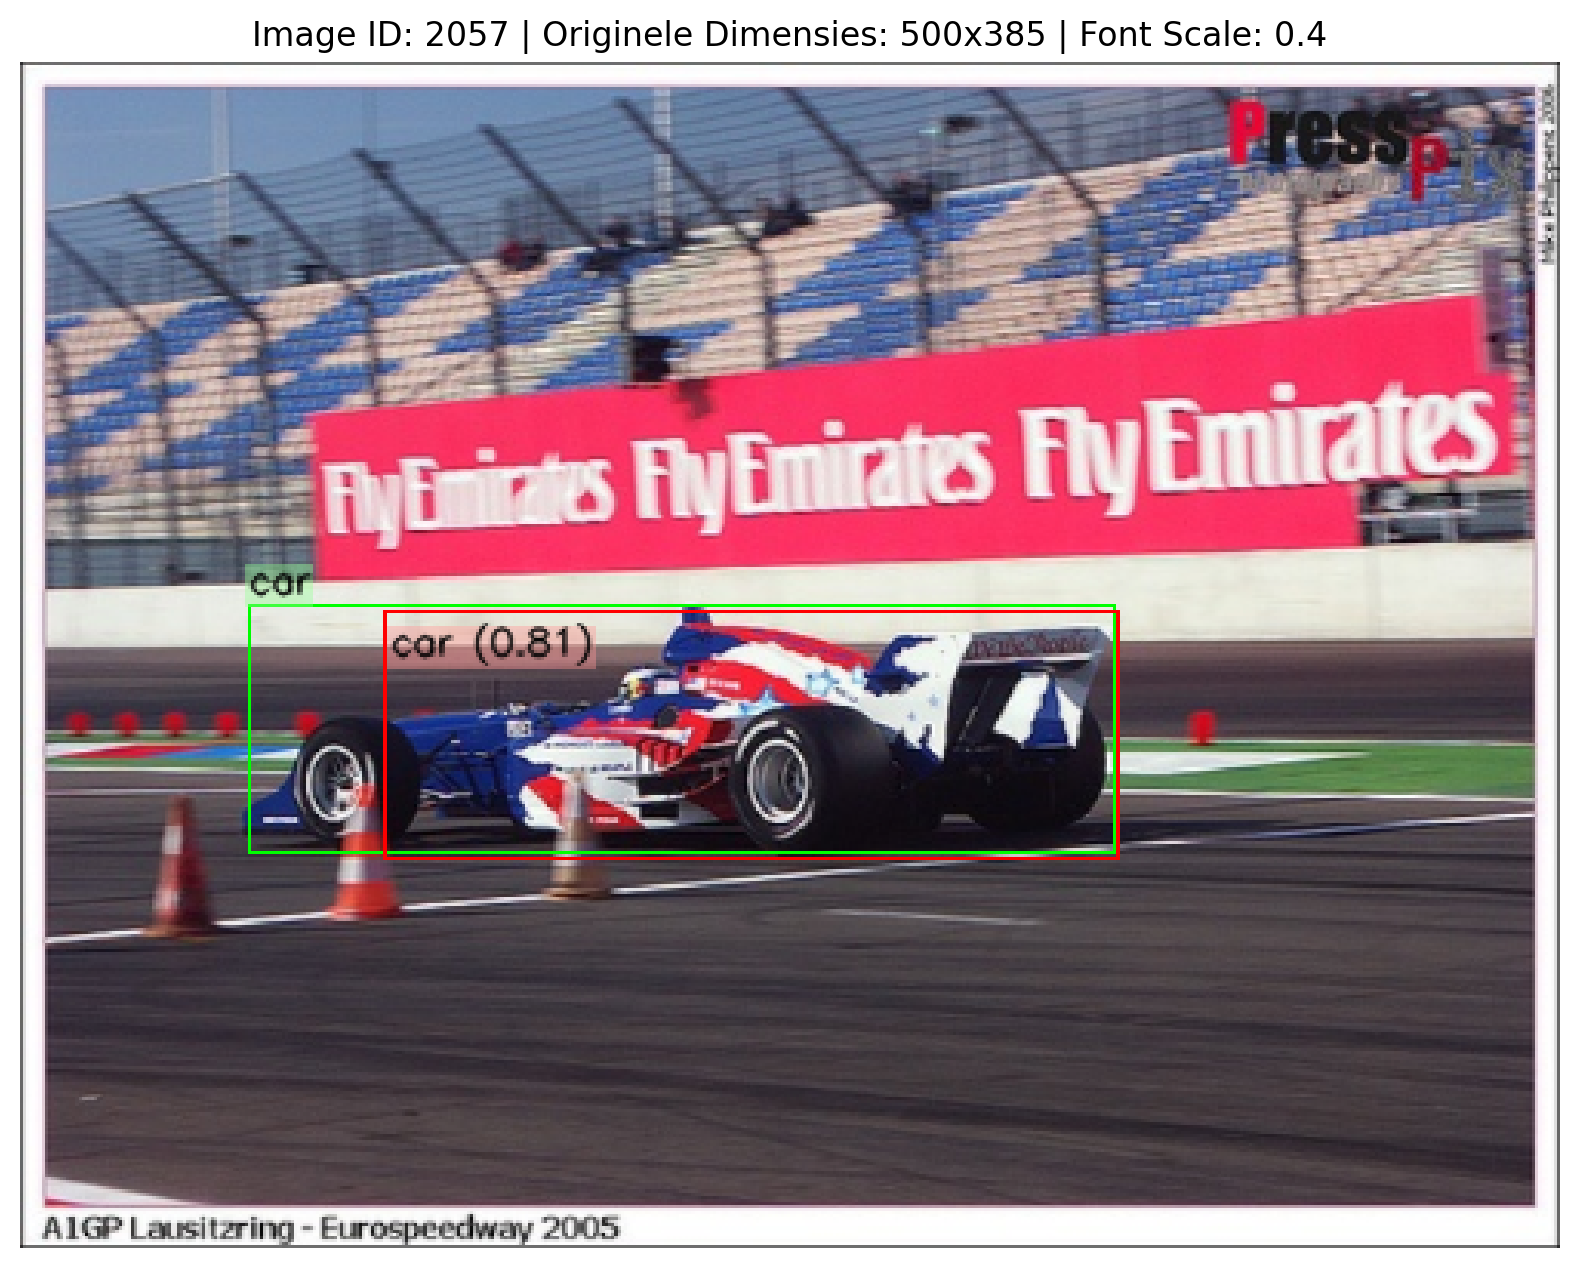

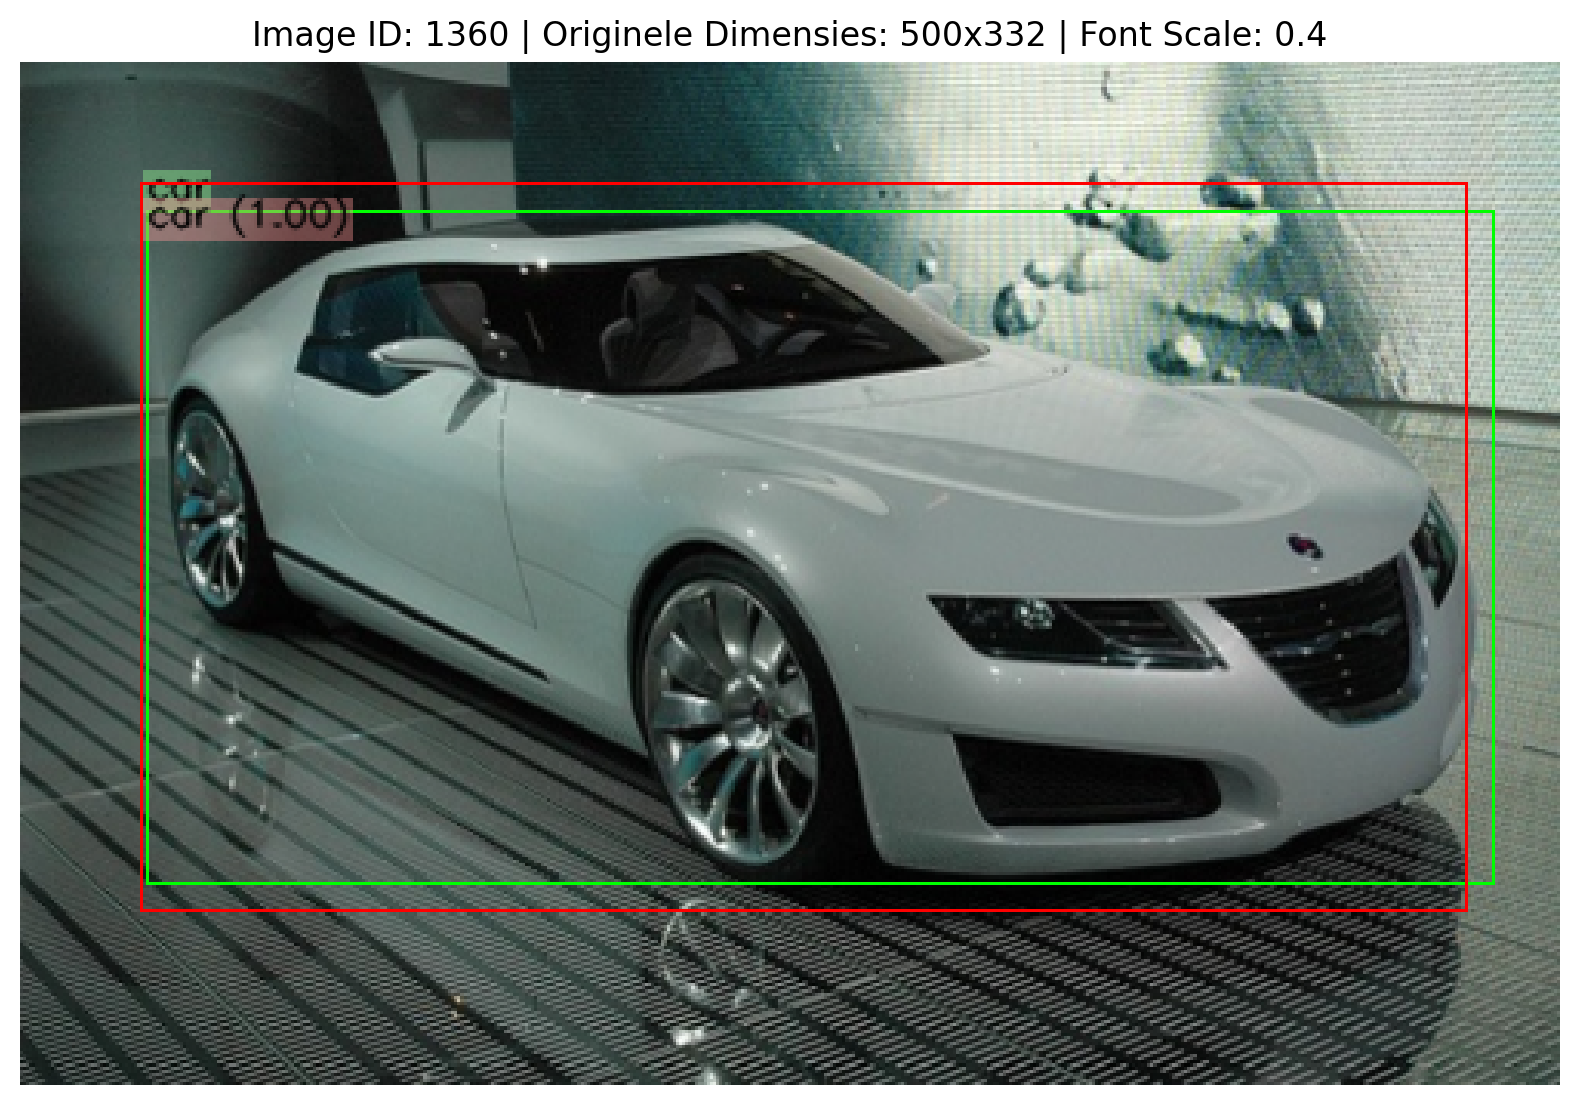

In [5]:
date = "09-03-2026-20-24-34"
MODEL_CHECKPOINT = os.path.join(ProjectPaths.OUTPUT_DIR, "..", "centralized", date, "best_model.pth")

# Voer de inspectie uit op 3 willekeurige plaatjes uit de batch
inspect_inference_original_size(
    model_path=MODEL_CHECKPOINT, 
    dataloader=poison_dl, 
    dataset=poison_ds, 
    num_images=3, 
    conf_threshold=0.55, # Pas dit aan om meer of minder voorspellingen te zien
    font_scale=0.4,
)

# Inference for poisoned and non-poisoned versions


In [25]:
from utils.global_settings import AttackType
TARGET_IMAGE_ID = 12
CONF_THRESHOLD = 0.5
FONT_SCALE = 0.4
SAVE_PATH = None 
MODEL_PATH = os.path.join(ProjectPaths.OUTPUT_DIR, "cluster", "2026-03-30-17-22-10", "latest_fl_checkpoint.pth")
# To alter the trigger that is inserted
BackdoorProperties.TRIGGER_PATTERN = TriggerType.FULL_NOISE
BackdoorProperties.ATTACK_TYPE = AttackType.GLOBAL_DISAPPEARANCE

In [26]:
# --- 1. DATASET INITIALISATIE ---
clean_ds = CustomCocoDataset(
    image_folder=ProjectPaths.VALIDATION_IMAGES_DIR,
    annotations_file=ProjectPaths.VALIDATION_ANNOTATIONS_FILE,
    width=BackdoorProperties.RESIZE_WIDTH,
    height=BackdoorProperties.RESIZE_HEIGHT,
    mode="always_clean", # Cruciaal om de backdoor te testen
)

clean_dl = DataLoader(
    poison_ds,
    batch_size=4, # Een kleine batch is genoeg voor visuele inspectie
    num_workers=0, # Altijd 0 in Jupyter om multiprocessing crashes te voorkomen
    collate_fn=FasterRCNNWrapper.get_collate_fn(),
    pin_memory=True,
    shuffle=True, # Zodat je elke keer andere plaatjes ziet
)

In [27]:
def find_dataset_index_by_image_id(dataset, image_id):
    """Find the dataset index that corresponds to a given COCO image_id."""
    for idx in range(len(dataset)):
        _, target = dataset[idx]
        if target["image_id"].item() == image_id:
            return idx
    raise ValueError(f"Image ID {image_id} not found in dataset")


def load_wrapper(model_path, num_classes, device):
    wrapper = FasterRCNNWrapper(num_classes=num_classes)
    checkpoint = torch.load(model_path, map_location=device)
    wrapper.set_weights(checkpoint["model_state_dict"])
    wrapper.model.to(device)
    wrapper.model.eval()
    return wrapper


def tensor_to_numpy(img_tensor):
    """Convert CHW float tensor to HWx3 uint8 RGB numpy array."""
    img = img_tensor.numpy().transpose(1, 2, 0)
    return (img * 255).astype(np.uint8).copy()


def draw_styled_text(img, text, pos, font_scale=0.4, alpha=0.4, is_pred=False):
    font = cv2.FONT_HERSHEY_SIMPLEX
    thickness = 1
    text_color = (0, 0, 0)
    bg_color = (255, 0, 0) if is_pred else (150, 255, 150)

    (w, h), baseline = cv2.getTextSize(text, font, font_scale, thickness)
    x, y = int(pos[0]), int(pos[1])
    p = 2

    x1, y1 = x - p, y - h - p
    x2, y2 = x + w + p, y + baseline + p

    ih, iw = img.shape[:2]
    x1, x2 = np.clip([x1, x2], 0, iw - 1).astype(int)
    y1, y2 = np.clip([y1, y2], 0, ih - 1).astype(int)

    sub_img = img[y1:y2, x1:x2]
    if sub_img.shape[0] > 0 and sub_img.shape[1] > 0:
        rect_overlay = np.full(sub_img.shape, bg_color, dtype=np.uint8)
        res = cv2.addWeighted(sub_img, 1 - alpha, rect_overlay, alpha, 0)
        img[y1:y2, x1:x2] = res

    cv2.putText(img, text, (x, y), font, font_scale, text_color, thickness, cv2.LINE_AA)


def draw_predictions(img, prediction, scale_w, scale_h, id_to_cat, conf_threshold, font_scale):
    """Draw red prediction boxes on the image."""
    pred_boxes = prediction['boxes'].cpu().numpy()
    pred_scores = prediction['scores'].cpu().numpy()
    pred_labels = prediction['labels'].cpu().numpy()

    mask = pred_scores > conf_threshold
    for box, score, label in zip(pred_boxes[mask], pred_scores[mask], pred_labels[mask]):
        x1, y1 = int(box[0] / scale_w), int(box[1] / scale_h)
        x2, y2 = int(box[2] / scale_w), int(box[3] / scale_h)
        class_name = id_to_cat.get(label, str(label))

        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 1)
        y_offset = int(35 * font_scale)
        draw_styled_text(img, f"{class_name} ({score:.2f})", (x1 + 2, y1 + y_offset),
                         font_scale=font_scale, is_pred=True)


def draw_ground_truth(img, target, scale_w, scale_h, id_to_cat, font_scale):
    """Draw green ground truth boxes on the image."""
    for box, label in zip(target['boxes'], target['labels']):
        x1, y1 = int(box[0].item() / scale_w), int(box[1].item() / scale_h)
        x2, y2 = int(box[2].item() / scale_w), int(box[3].item() / scale_h)
        class_name = id_to_cat.get(label.item(), str(label.item()))

        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 1)
        draw_styled_text(img, class_name, (x1, max(y1 - 4, 10)), font_scale=font_scale)


def rescale_to_original(img_np, scale_w, scale_h):
    orig_w = int(img_np.shape[1] / scale_w)
    orig_h = int(img_np.shape[0] / scale_h)
    return cv2.resize(img_np, (orig_w, orig_h))

In [28]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = clean_ds.get_total_classes_count() + 1
id_to_cat = {v: k for k, v in clean_ds.cat_to_id_map.items()}

# Load both models
print("Loading model...")
wrapper = load_wrapper(MODEL_PATH, num_classes, device)

# Find the image in both datasets
clean_idx = find_dataset_index_by_image_id(clean_ds, TARGET_IMAGE_ID)
poison_idx = find_dataset_index_by_image_id(poison_ds, TARGET_IMAGE_ID)

clean_img, clean_target = clean_ds[clean_idx]
poison_img, poison_target = poison_ds[poison_idx]

scale_w = clean_target['image_scale'][0].item()
scale_h = clean_target['image_scale'][1].item()

# Run inference
with torch.inference_mode():
    clean_pred = wrapper.model([clean_img.to(device)])[0]
    poison_pred = wrapper.model([poison_img.to(device)])[0]

print("Done with clean and poisoned predictions")

Loading model...
Done with clean and poisoned predictions


In [29]:
# Panel 1: Original image with ground truth only
original_np = rescale_to_original(tensor_to_numpy(clean_img), scale_w, scale_h)
# draw_ground_truth(original_np, clean_target, scale_w, scale_h, id_to_cat, FONT_SCALE)

# Panel 2: Clean image + clean model predictions
clean_np = rescale_to_original(tensor_to_numpy(clean_img), scale_w, scale_h)
draw_ground_truth(clean_np, clean_target, scale_w, scale_h, id_to_cat, FONT_SCALE)
draw_predictions(clean_np, clean_pred, scale_w, scale_h, id_to_cat, CONF_THRESHOLD, FONT_SCALE)

# Panel 3: Poisoned image + backdoored model predictions
poison_np = rescale_to_original(tensor_to_numpy(poison_img), scale_w, scale_h)
draw_ground_truth(poison_np, poison_target, scale_w, scale_h, id_to_cat, FONT_SCALE)
draw_predictions(poison_np, poison_pred, scale_w, scale_h, id_to_cat, CONF_THRESHOLD, FONT_SCALE)

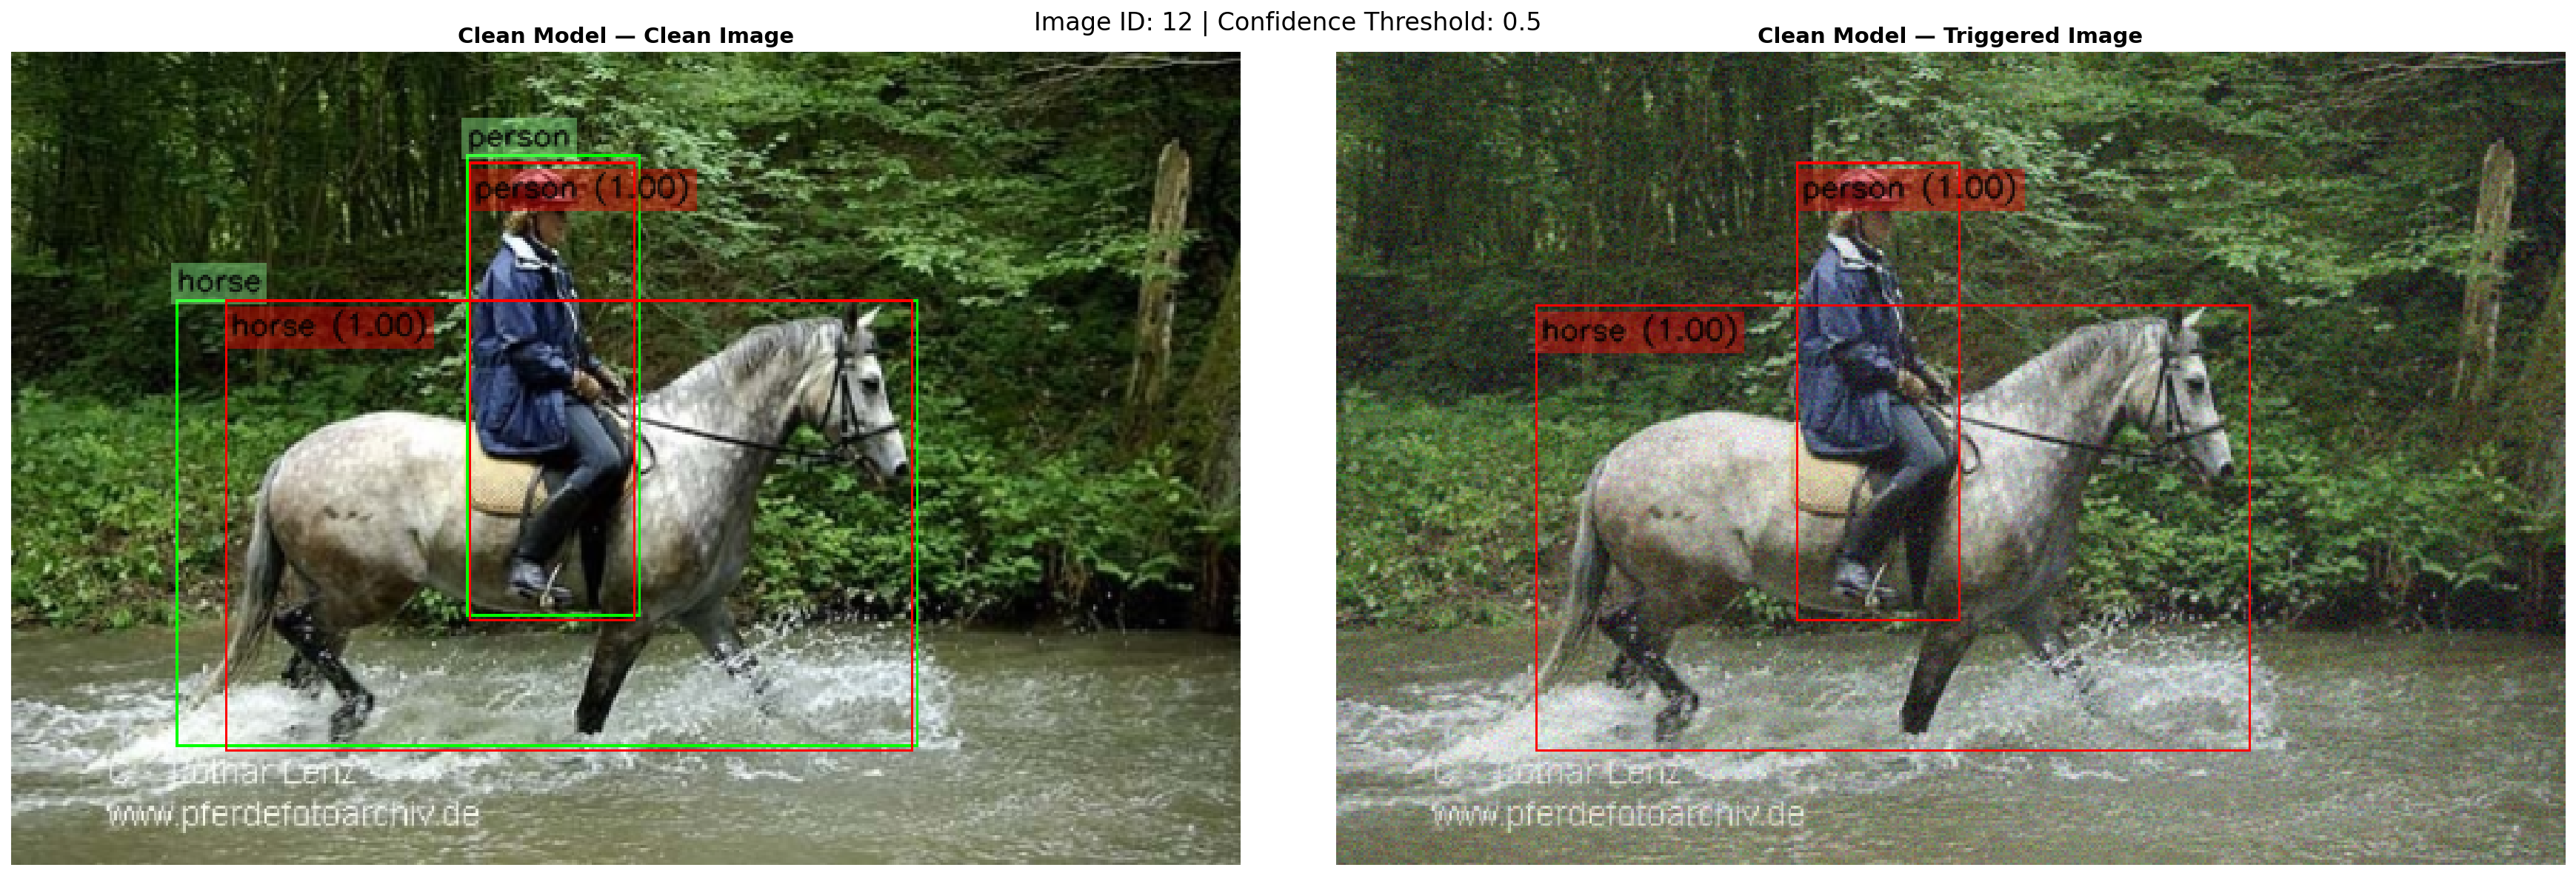

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(24, 8), dpi=150)
# fig, axes = plt.subplots(1, 3, figsize=(24, 8), dpi=150)

# titles = [
#     "Original Image",
#     "Backdoored Model — Clean Image",
#     "Backdoored Model — Triggered Image"
# ]
titles = [
    "Clean Model — Clean Image",
    "Clean Model — Triggered Image"
]
panels = [clean_np, poison_np]
# panels = [original_np, clean_np, poison_np]

for ax, img, title in zip(axes, panels, titles):
    ax.imshow(img)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.axis('off')

fig.suptitle(f"Image ID: {TARGET_IMAGE_ID} | Confidence Threshold: {CONF_THRESHOLD}",
             fontsize=16, y=0.98)
plt.tight_layout()

if SAVE_PATH:
    fig.savefig(SAVE_PATH, bbox_inches='tight', dpi=200)
    print(f"Saved to {SAVE_PATH}")

plt.show()